# SmokeCheck: should practice move indoors tomorrow?

**Veritas AI International High School Hackathon 2026 · Track: AI + Climate**
(built on suggested project 4.3.2, next-day air quality forecast)

**One-sentence pitch:** SmokeCheck helps a Midwest high-school athletic director who has to plan tomorrow's
practice by taking today's air-quality readings and tomorrow's weather forecast, and telling them whether to
expect unhealthy smoke (a daily average above 35 µg/m³ of PM2.5).

**How to run:** Runtime → Run all. It needs no API keys or uploads, and finishes in under a minute.

In [1]:
# Our numbers come from scikit-learn 1.9.1. Older versions (which Colab may have) give slightly different warning counts.
%pip install -q scikit-learn==1.9.1

Note: you may need to restart the kernel to use updated packages.


## 1. Load the data

Small files, all built by the scripts in this repo (`fetch_*.py`):

- `data/daily.csv`, one row per city per day for six Midwest metro areas:
  - `obs_pm25`: what EPA monitors **measured**, averaged over the metro area (µg/m³). This is what we forecast.
  - `cams_pm25`: what the CAMS global air-quality **model** says (via Open-Meteo). An estimate on a 45 km grid, not a measurement.
  - weather from Open-Meteo: temperature, humidity, rain, wind speed and wind direction (`wind_u`, `wind_v`).
- `data/smoke_days.csv`: whether NOAA analysts drew a wildfire-smoke plume over the city on satellite images
  (`smoke`: 0 none, 1 light, 2 medium, 3 heavy).
- `data/weather_dayahead_2025.csv`: for 2025 only, the weather that was **forecast one day ahead**.
  Section 7 explains why we need it.
- `data/naqfc_dayahead.csv`: NOAA's official air-quality forecast (NAQFC), the run issued the morning
  before each target day. It's a baseline in section 5, and since our second model change also an input (section 4).
- `data/ring_pm25.csv`: EPA readings in a ring of 14 more metro areas around our six (`fetch_ring.py`).
- `data/evening_pm25.csv`: each city's EPA hourly readings averaged from 2 to 7 PM (`fetch_evening.py`).

In [2]:
import json
import os

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def load(name):
    """Read a file from the repo's data folder, or from GitHub when the notebook runs on its own in Colab."""
    local = f"data/{name}"
    return pd.read_csv(local if os.path.exists(local) else f"https://raw.githubusercontent.com/fruutium/smokecheck/main/{local}")


daily = load("daily.csv").merge(load("smoke_days.csv")[["city", "date", "smoke"]], on=["city", "date"])
daily = daily.merge(load("naqfc_dayahead.csv")[["city", "date", "naqfc_pm25"]], on=["city", "date"], how="left")
daily = daily.merge(load("ring_pm25.csv")[["date", "ring_max", "ring_mean", "north_max"]], on="date", how="left")
daily = daily.merge(load("evening_pm25.csv")[["city", "date", "evening_pm25"]], on=["city", "date"], how="left")
dayahead_wx = load("weather_dayahead_2025.csv")

THRESHOLD = 35  # µg/m³, the US EPA 24-hour PM2.5 standard. A "bad day" is a daily average above it.
print(f"{len(daily):,} city-days, {daily['city'].nunique()} cities, {daily['date'].min()} to {daily['date'].max()}")
daily.head()

7,476 city-days, 6 cities, 2022-08-04 to 2025-12-31


,city,date,cams_pm25,cams_pm25_max,cams_hours,temp_c,humidity,precip_mm,wind_kmh,wind_u,...,n_monitors,lat,lon,split,smoke,naqfc_pm25,ring_max,ring_mean,north_max,evening_pm25
0,Chicago,2022-08-04,9.54,17.8,24,22.67,87.17,6.4,10.80,-0.09,...,12.0,41.88,-87.63,train,1,NaN,10.36,5.48,10.36,7.62
1,Chicago,2022-08-05,12.52,16.9,24,23.28,89.08,0.0,7.16,-4.94,...,12.0,41.88,-87.63,train,1,3.80,15.92,7.79,15.92,8.50
2,Chicago,2022-08-06,13.20,17.1,24,27.45,75.04,0.0,9.52,-0.43,...,22.0,41.88,-87.63,train,1,8.39,12.73,8.09,3.69,9.45
3,Chicago,2022-08-07,11.92,15.7,24,25.04,87.21,0.8,6.88,3.79,...,12.0,41.88,-87.63,train,0,8.54,8.41,5.46,5.05,4.85
4,Chicago,2022-08-08,10.27,20.8,24,21.75,89.29,0.8,13.13,4.36,...,12.0,41.88,-87.63,train,0,7.45,8.69,4.46,8.69,3.54


## 2. Look at the data first

Days above 35 µg/m³ are rare (about 1 in 100), and in summer they are almost all wildfire smoke.
June 2023 (smoke from Quebec) is by far the worst event, so most of the bad days we can learn from come from one event.

year         2022  2023  2024  2025  All
city                                    
Chicago         0     5     0     3    8
Detroit         0     7     1     6   14
Madison         0     8     0     6   14
Milwaukee       0     7     0     9   16
Minneapolis     0     8     1     9   18
St. Louis       0     1     0     2    3
All             0    36     2    35   73


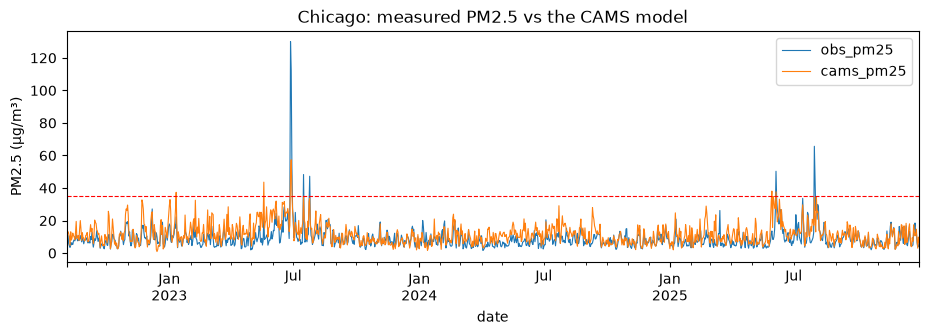

In [3]:
daily["bad"] = daily["obs_pm25"] > THRESHOLD
daily["year"] = daily["date"].str[:4]
print(daily.pivot_table(index="city", columns="year", values="bad", aggfunc="sum", margins=True))

chicago = daily[daily["city"] == "Chicago"].set_index(pd.to_datetime(daily.loc[daily["city"] == "Chicago", "date"]))
ax = chicago[["obs_pm25", "cams_pm25"]].plot(figsize=(11, 3), lw=0.8, title="Chicago: measured PM2.5 vs the CAMS model")
ax.axhline(THRESHOLD, color="red", ls="--", lw=0.8)
ax.set_ylabel("PM2.5 (µg/m³)");

## 3. Split by time

We train on earlier dates and test on later ones, and never shuffle days together:
**train = Aug 2022 to Dec 2024, test = all of 2025.** The test year has its own smoke season
(June and late July / early August 2025). We don't use it to choose anything, and each model is scored on it once,
in section 7. (We did look at earlier models' 2025 results before our second model change; see the note in section 6.)

In [4]:
print(daily.groupby("split").agg(first_day=("date", "min"), last_day=("date", "max"),
                                 city_days=("date", "size"), bad_days=("bad", "sum")))

        first_day    last_day  city_days  bad_days
split                                             
test   2025-01-01  2025-12-31       2190        35
train  2022-08-04  2024-12-31       5286        38


## 4. What we know the evening before

The athletic director decides the evening before. So each row is one **target day** (tomorrow), and the
inputs are only things known by then:

- **this city's readings:** today, yesterday and the day before (`obs_1`, `obs_2`, `obs_3`), and today's change
- **the region:** today's highest and average reading across all six cities. Smoke drifts across the Midwest, so
  a smoky Minneapolis today can mean a smoky Chicago tomorrow.
- **smoke maps:** today's NOAA plume over this city, and the heaviest plume over any of the six cities
- **the CAMS model today**, and how far off it was today compared with the monitors (`cams_miss_today`)
- **tomorrow's weather forecast:** rain washes smoke out, wind direction says where air comes from
- the day of the year, and which city it is

Added in our second model change (section 6 explains how we decided):

- **NOAA's forecast for tomorrow** (`naqfc_tomorrow`): the official NAQFC forecast for the target day, from the run
  issued at 6 AM Central the day before. A physics model that tracks smoke plumes; our model learns how far to trust
  it next to the local readings. Three run days in 2022-23 have no forecast; on those 18 rows we use today's reading.
- **a wider ring of monitors** (`ring_max_today`, `ring_mean_today`, `north_max_today`): today's EPA readings in 14
  metro areas around our six (Duluth, Fargo, Bismarck, St. Cloud, Sioux Falls, Rochester MN, Des Moines,
  Cedar Rapids, Green Bay, Grand Rapids, Lansing, Indianapolis, Kansas City, Omaha): the highest, the average, and
  the highest of the 4 north of 45°N, which Canadian smoke crosses first.
- **this afternoon's reading** (`evening_today`): this city's average hourly reading from 2 to 7 PM today (EPA hours
  are in standard time, so 3 to 8 PM in summer). Smoke often arrives late in the day, and the daily average hides it.

In [5]:
def add_features(df):
    df = df.sort_values(["city", "date"]).copy()
    by_city = df.groupby("city")
    for k in (1, 2, 3):
        df[f"obs_{k}"] = by_city["obs_pm25"].shift(k)  # shift(1) moves today's value onto tomorrow's row
    df["change_today"] = df["obs_1"] - df["obs_2"]
    df["cams_today"] = by_city["cams_pm25"].shift(1)
    df["cams_max_today"] = by_city["cams_pm25_max"].shift(1)
    df["cams_miss_today"] = df["obs_1"] - df["cams_today"]
    df["smoke_today"] = by_city["smoke"].shift(1)
    region = df.groupby("date").agg(region_max_today=("obs_pm25", "max"), region_mean_today=("obs_pm25", "mean"),
                                    region_smoke_today=("smoke", "max")).shift(1)  # shift(1): today's, not tomorrow's
    df = df.join(region, on="date")
    df["day_of_year"] = pd.to_datetime(df["date"]).dt.day_of_year
    df["city_id"] = df["city"].astype("category").cat.codes
    # NOAA's forecast FOR the target day, issued the morning before, so no shift. Missing (18 rows) -> today's reading.
    df["naqfc_tomorrow"] = df["naqfc_pm25"].fillna(df["obs_1"])
    ring = df.groupby("date")[["ring_max", "ring_mean", "north_max"]].first().shift(1)  # shift(1): today's ring
    df = df.join(ring.add_suffix("_today"), on="date")
    df["evening_today"] = by_city["evening_pm25"].shift(1)  # this afternoon, 2-7 PM
    return df.dropna(subset=["obs_3"]).reset_index(drop=True)  # the first three days have no history


FEATURES = ["obs_1", "obs_2", "obs_3", "change_today", "region_max_today", "region_mean_today",
            "smoke_today", "region_smoke_today", "cams_today", "cams_max_today", "cams_miss_today",
            "temp_c", "humidity", "precip_mm", "wind_kmh", "wind_u", "wind_v", "day_of_year", "city_id",
            "naqfc_tomorrow", "ring_max_today", "ring_mean_today", "north_max_today", "evening_today"]
ORIGINAL = FEATURES[:FEATURES.index("city_id") + 1]  # the inputs before our second model change
WEATHER = ["temp_c", "humidity", "precip_mm", "wind_kmh", "wind_u", "wind_v"]

df = add_features(daily)
assert df[FEATURES].notna().all().all()  # Ridge can't take a missing value
train = df[df["split"] == "train"].copy()
print(f"training rows: {len(train):,}   features: {len(FEATURES)}")

training rows: 5,268   features: 24


## 5. Baselines: four forecasts our model has to beat

1. **Persistence:** tomorrow will be the same as today.
2. **Climatology:** tomorrow will be the average for this city and month (from the training years only).
3. **NOAA's official forecast (NAQFC):** what the US National Air Quality Forecast Capability predicted for the
   target day's average PM2.5, in its 12Z run the day before (6 am Central). This is the professional forecast
   an athletic director could really have looked up. We take the grid cell nearest the city centre. Its
   24-hour window runs 10 pm to 10 pm Central, 22 of the 24 hours of EPA's day. NOAA upgraded the model in May 2024.
4. **Raw CAMS:** the CAMS model's number for the target day. Open-Meteo does not keep what CAMS predicted
   *a day ahead*: we checked, and its "previous day" values are empty for 2022 to 2025. The CAMS history it
   serves is stitched from short-range runs that already "see" the smoke. So this baseline is **stronger than
   any real day-ahead forecast**, and we don't let our model use it. We keep it as an optimistic upper bar.

In [6]:
df["month"] = df["date"].str[5:7].astype(int)
df = df.join(train.assign(month=train["date"].str[5:7].astype(int))
             .groupby(["city", "month"])["obs_pm25"].mean().rename("pred_climatology"), on=["city", "month"])
df["pred_persistence"] = df["obs_1"]
df["pred_noaa"] = df["naqfc_pm25"]
df["pred_cams"] = df["cams_pm25"]
train = df[df["split"] == "train"].copy()

## 6. Choose the model and the warning rule, using the training years only

**Checking choices without touching 2025.** We hide one training year at a time (Aug-Dec 2022, 2023, 2024),
train on the other two, and predict the hidden one. Each year is kept whole, so days are never mixed.
Every training day then gets a prediction from a model that never saw it.

**Two models, averaged:**
- a **Ridge regression** (a weighted sum of the inputs). It can go higher than anything it has seen,
  which matters when smoke is worse than the training years.
- a **gradient-boosted tree model** that predicts **the change from today**, not the level. Trees can't predict
  values outside the range they were trained on, but a change added to today's reading can be large.

In [7]:
def make_ridge():
    # StandardScaler puts every input on the same scale, so Ridge's penalty treats them equally
    return make_pipeline(StandardScaler(), Ridge(alpha=1.0))


def make_trees(loss="absolute_error"):
    return HistGradientBoostingRegressor(loss=loss, max_iter=300, learning_rate=0.05, random_state=0,
                                         categorical_features=[FEATURES.index("city_id")])


def fit(rows):
    ridge = make_ridge().fit(rows[FEATURES].drop(columns="city_id"), rows["obs_pm25"])
    trees = make_trees().fit(rows[FEATURES], rows["obs_pm25"] - rows["obs_1"])
    return ridge, trees


def predict(models, rows):
    ridge, trees = models
    from_ridge = ridge.predict(rows[FEATURES].drop(columns="city_id")).clip(min=0)
    from_trees = rows["obs_1"] + trees.predict(rows[FEATURES])
    return (from_ridge + from_trees) / 2


train["block"] = np.where(train["date"] < "2023-01-01", "2022 (Aug-Dec)", train["date"].str[:4])
train["pred_model"] = np.nan
train["pred_trees_level"] = np.nan  # the version we tried first and dropped (see below)
fold_models = {}  # kept for the "what does the model rely on" check below
for block in train["block"].unique():
    seen, hidden = train[train["block"] != block], train[train["block"] == block]
    fold_models[block] = fit(seen)
    train.loc[hidden.index, "pred_model"] = predict(fold_models[block], hidden)
    plain = make_trees("squared_error").fit(seen[ORIGINAL], seen["obs_pm25"])  # as first tried, before the new inputs
    train.loc[hidden.index, "pred_trees_level"] = plain.predict(hidden[ORIGINAL])

print("bad days in each training block:", train.groupby("block")["bad"].sum().to_dict())

bad days in each training block: {'2022 (Aug-Dec)': 0, '2023': 36, '2024': 2}


**The warning rule.** A forecast becomes a warning ("move practice indoors") when it goes above a cut-off.
The cut-off doesn't have to be 35: a forecast that tends to come in low should warn earlier.

We fixed the rule that **one missed bad day costs as much as 5 false alarms** before scoring our model on 2025
(we had already seen the baselines' 2025 numbers at a plain 35 line). Sending kids to run in smoke is much worse
than an unneeded indoor practice, but if SmokeCheck cries wolf every week, the athletic director stops listening.

**Picking the cut-off.** On the training years, many cut-offs cost almost the same, so simply taking the one with
the lowest cost picks out noise. (We found this the hard way: storing the readings with one more decimal place,
a change of at most 0.005 µg/m³, moved our model's lowest-cost cut-off from 24 to 29.5.) So for **every**
forecast, baselines included, we make 200 reshuffled copies of the training years by drawing whole calendar weeks
at random (a smoke event stays together), find the lowest-cost cut-off on each copy, and use the **median**.

In [8]:
COST_OF_A_MISS = 5


def warning_counts(rows, col, warn_at):
    real, warned = rows["obs_pm25"] > THRESHOLD, rows[col] > warn_at
    return {"caught": int((real & warned).sum()), "missed": int((real & ~warned).sum()),
            "false_alarms": int((~real & warned).sum())}


CUT_OFFS = np.arange(10, 60.5, 0.5)  # every cut-off we consider, in µg/m³


def cost_by_cut_off(rows, col):
    """5 x missed + false alarms, for every cut-off in CUT_OFFS at once."""
    rows = rows[rows[col].notna()]  # NOAA has no forecast for 3 run days in 2022-23
    real = rows["obs_pm25"].to_numpy()[:, None] > THRESHOLD
    warned = rows[col].to_numpy()[:, None] > CUT_OFFS[None, :]
    return COST_OF_A_MISS * (real & ~warned).sum(axis=0) + (~real & warned).sum(axis=0)


def best_cut_off(rows, col, copies=200):
    """Median, over copies of the rows made by drawing whole weeks with replacement, of the lowest-cost cut-off."""
    week = pd.to_datetime(rows["date"]).dt.to_period("W").astype(str).to_numpy()
    rows_of_week = {w: np.flatnonzero(week == w) for w in np.unique(week)}
    weeks = list(rows_of_week)
    rng = np.random.default_rng(0)  # fixed seed, so the notebook gives the same answer every run
    best = []
    for _ in range(copies):
        picked = np.concatenate([rows_of_week[w] for w in rng.choice(weeks, len(weeks))])
        best.append(CUT_OFFS[np.argmin(cost_by_cut_off(rows.iloc[picked], col))])
    return float(np.median(best))


FORECASTS = ["pred_persistence", "pred_climatology", "pred_noaa", "pred_cams", "pred_model"]
warn_at = {col: float(best_cut_off(train, col)) for col in FORECASTS + ["pred_trees_level"]}


def score(rows, col):
    """Average error, plus warnings using that forecast's own cut-off."""
    rows = rows[rows[col].notna()]
    out = {"mae": round(float((rows[col] - rows["obs_pm25"]).abs().mean()), 2), "days": int(len(rows)),
           "bad_days": int((rows["obs_pm25"] > THRESHOLD).sum()), "warn_at": warn_at[col]}
    out.update(warning_counts(rows, col, warn_at[col]))
    out["recall"] = round(out["caught"] / out["bad_days"], 3) if out["bad_days"] else None
    return out


print("Training years, each predicted by a model that didn't see that year")
print(pd.DataFrame({col: score(train, col) for col in FORECASTS + ["pred_trees_level"]}).T)

Training years, each predicted by a model that didn't see that year
                   mae    days  bad_days  warn_at  caught  missed  \
pred_persistence  3.23  5268.0      38.0     37.0    17.0    21.0   
pred_climatology  3.89  5268.0      38.0     19.5     0.0    38.0   
pred_noaa         3.38  5250.0      38.0     52.5     6.0    32.0   
pred_cams         3.79  5268.0      38.0     30.0    27.0    11.0   
pred_model        2.22  5268.0      38.0     32.0    18.0    20.0   
pred_trees_level  2.73  5268.0      38.0     43.0     1.0    37.0   

                  false_alarms  recall  
pred_persistence          18.0   0.447  
pred_climatology           0.0   0.000  
pred_noaa                 23.0   0.158  
pred_cams                 40.0   0.711  
pred_model                12.0   0.474  
pred_trees_level           2.0   0.026  


**What does the model rely on?** For each group of inputs, we shuffle that group's values among the days of the
hidden year (the group's columns move together), predict again with the same fitted models, and see how much the
average error rises. A big rise means the model leans on that group. We repeat each shuffle 3 times and average.
Two caveats: `cams_miss_today` is built from today's reading, and the trees add their change to today's reading,
so shuffling "this city's readings" also scrambles those; and groups that carry the same news (the region and the
smoke maps both see a smoke event) can stand in for each other, so each one can look less needed than it is.

In [9]:
GROUPS = {"this city's readings": ["obs_1", "obs_2", "obs_3", "change_today"],
          "region (six cities today)": ["region_max_today", "region_mean_today"],
          "smoke maps": ["smoke_today", "region_smoke_today"], "CAMS today": ["cams_today", "cams_max_today", "cams_miss_today"],
          "tomorrow's weather": WEATHER, "day of year": ["day_of_year"], "which city": ["city_id"],
          "NOAA's forecast for tomorrow": ["naqfc_tomorrow"],
          "ring of 14 metros today": ["ring_max_today", "ring_mean_today", "north_max_today"],
          "this afternoon (2-7 PM)": ["evening_today"]}
assert sorted(sum(GROUPS.values(), [])) == sorted(FEATURES)
rng = np.random.default_rng(0)


def out_of_fold_errors(rows):
    """Each row's error, predicted by the model that didn't see its block."""
    pred = pd.concat([predict(fold_models[block], g) for block, g in rows.groupby("block")]).reindex(rows.index)
    return (pred - rows["obs_pm25"]).abs()


def shuffled(rows, cols):
    rows = rows.copy()
    for _block, g in rows.groupby("block"):
        rows.loc[g.index, cols] = g[cols].sample(frac=1, random_state=rng).to_numpy()
    return rows


base = out_of_fold_errors(train)
rise = {name: np.mean([out_of_fold_errors(shuffled(train, cols)) - base for _ in range(3)], axis=0)
        for name, cols in GROUPS.items()}
print("Rise in average error when one group is shuffled (µg/m³), training years, out-of-fold:")
print(pd.DataFrame({"all days": {n: r.mean() for n, r in rise.items()},
                    "the 38 bad days": {n: r[train["bad"].to_numpy()].mean() for n, r in rise.items()}})
      .sort_values("all days", ascending=False).round(2))

Rise in average error when one group is shuffled (µg/m³), training years, out-of-fold:
                              all days  the 38 bad days
NOAA's forecast for tomorrow      0.70             3.20
this city's readings              0.67            15.71
tomorrow's weather                0.28             0.06
ring of 14 metros today           0.21             1.91
this afternoon (2-7 PM)           0.06             0.55
which city                        0.02            -0.06
CAMS today                        0.02             0.34
region (six cities today)         0.01            -0.20
day of year                       0.01            -0.05
smoke maps                        0.00            -0.08


**What we tried and dropped:** one tree model predicting the PM2.5 level directly (`pred_trees_level`).
Its average error was good, but it caught almost none of the bad days. When 2023 is hidden, the other
training years have only 2 bad days and a highest reading of 48, and a tree model can't predict above what
it has seen. Predicting the change from today, and averaging with Ridge, fixed most of that.

**Also tried and dropped: upwind smoke.** Smoke that reaches the Midwest often comes from Canada, so we added
the heaviest NOAA-mapped smoke 300, 600 and 900 km upwind of each city today (`fetch_upwind_smoke.py`). Upwind
smoke came before 16 of the 21 training arrival days, against 17% of ordinary days, so the signal is real. But on
the training-year check it changed nothing (average error 2.49 with or without it), so we left it out. Our guess:
when 2023 is hidden, the other training years have only 2 bad days, so the model can't learn what upwind smoke means.
We also noticed that leaving out just six rows moved the training-year warning count by a few days. With 38 bad
days, mostly from one event, warning numbers are noisy; the average error is much steadier.

**Also tried and dropped: more years of history (2018 to mid-2022).** To give the model more smoke seasons,
`fetch_early.py` adds the 4.6 years before our data starts (`data/daily_early.csv`: EPA readings, the same
Open-Meteo weather archive, NOAA smoke maps). CAMS doesn't exist on Open-Meteo before August 2022, so the longer
model leaves out the three CAMS inputs. The extra years have few bad days: 7, and only 3 of them are smoke
(Minneapolis, July 29-31, 2021). Three are probably Fourth of July fireworks in 2020 (July 4-5, no smoke on the
NOAA maps) and one is a December day in Detroit; the September 2020 western smoke never pushed a city's daily
average above 35. Before running the comparison we wrote down the rule: adopt the longer model only if, on the same 2022-2024 days, its average error is lower
**and** its warning cost (5 × missed + false alarms) isn't higher. `compare_seasons.py` hides one year at a time:

(This comparison was run before we switched to the median-of-copies cut-off, so its cut-offs are the single
lowest-cost ones; the error column doesn't depend on that.)

| Training-year check, 2022-08-07 to 2024 (38 bad days) | average error | warn above | caught | missed | false alarms | cost | arrival days caught |
|---|---|---|---|---|---|---|---|
| earlier model (before the new inputs) | 2.49 | 24 | 21 | 17 | 26 | 111 | 4 of 21 |
| earlier model without CAMS | 2.48 | 29.5 | 18 | 20 | 12 | 112 | 1 of 21 |
| 2018-2024, without CAMS | 2.38 | 27.5 | 18 | 20 | 15 | 115 | 1 of 21 |
| 2018-2024, without CAMS, plus upwind smoke | 2.39 | 30 | 17 | 21 | 11 | 116 | 1 of 21 |

More years lowered the average error in every hidden year (by 0.06 to 0.15), but the warning cost went up a
little, so by our rule we kept the model we had then and never scored the longer one on 2025. What we learned:
dropping CAMS alone took arrival-day catches from 4 to 1 of 21 (each at its own cut-off). With numbers this
small that's a hint that CAMS helps on arrival days, not proof. Upwind smoke still didn't help, but the extra
years add only 3 smoke bad days, so this was a weak test of our guess about it. A cost gap of 4 is less than one missed day, so the call is close. A version that
keeps CAMS where it exists might get both; we didn't try it, because we had decided not to add variants after
seeing these results.

**Our second model change: three new inputs, adopted.** Everything above was checked on the earlier model
(training-year error 2.49). Its weak spot was arrival days, so we tried three inputs that could see smoke coming,
all known the evening before (section 4): **(a)** NOAA's forecast for tomorrow, **(b)** today's readings in a ring
of 14 more metro areas, **(c)** this city's 2-7 PM reading. Before building any of them we wrote down and
committed the rule (`compare_features.py`): compare the variants below on the same training rows, hiding one year
at a time; take the one with the lowest average error, and adopt it only if that error is at least 0.05 below
2.49 **and** its warning cost (at its own cut-off, chosen the same way as above) is at most 5 above the earlier
model's 117. No falling back to the runner-up.

| Training-year check, 2022-08-07 to 2024 (38 bad days) | average error | warn above | caught | false alarms | cost | arrival days caught |
|---|---|---|---|---|---|---|
| earlier model | 2.49 | 24.5 | 19 | 22 | 117 | 2 of 21 |
| + NOAA's forecast (a) | 2.27 | 30 | 20 | 20 | 110 | 3 of 21 |
| + ring of metros (b) | 2.40 | 25.5 | 20 | 21 | 111 | 3 of 21 |
| + afternoon reading (c) | 2.45 | 24.5 | 21 | 24 | 109 | 4 of 21 |
| + a + b | 2.23 | 28 | 21 | 29 | 114 | 4 of 21 |
| **+ a + b + c (adopted)** | **2.22** | 32 | 18 | 12 | 112 | 2 of 21 |

All three together had the lowest error, lower in every hidden year (2022: 2.00 → 1.69, 2023: 3.19 → 2.96,
2024: 2.00 → 1.69), and its cost passed the limit, so it is the model in this notebook. Most of the gain comes
from NOAA's forecast (the shuffle check above agrees). It did **not** catch more arrival days on the training
years: the gain is in everyday accuracy, not in the hard cases.

**An honest note on the test year.** We had already scored the earlier model on 2025 (several times while we built
the project; the decision log has each look). This change was planned after those looks, so 2025 is no longer a
perfectly untouched test. To keep it as clean as we could, the inputs, the variants and the rule were fixed and
committed before any of them was scored, the choice used the training years only, and 2025 was scored once,
for the adopted model only. The other variants were never run on 2025.

## 7. The test: 2025, scored once

We train on all the training years and predict every day of 2025. (This is the first and only 2025 score of this
model; the earlier model's 2025 results are in section 6's note and the table at the end of this section.)

**Weather honesty.** The weather in our main table is almost the real weather (Open-Meteo stitches it from
the first hours of each forecast). The evening before, the athletic director only has a forecast. For 2025,
Open-Meteo keeps the forecast made one day earlier, so **the test uses that day-ahead forecast**. (We had to
train on the stitched weather, because day-ahead forecasts don't exist for 2022-2023.)

In [10]:
models = fit(train)
test = df[df["split"] == "test"].copy()
test["pred_model_with_stitched_weather"] = predict(models, test)  # for comparison only
test = test.drop(columns=WEATHER).merge(dayahead_wx, on=["city", "date"])
test["pred_model"] = predict(models, test)
warn_at["pred_model_with_stitched_weather"] = warn_at["pred_model"]

results = pd.DataFrame({col: score(test, col) for col in FORECASTS + ["pred_model_with_stitched_weather"]}).T
print("Test year 2025, all six cities")
results

Test year 2025, all six cities


,mae,days,bad_days,warn_at,caught,missed,false_alarms,recall
pred_persistence,3.40,2190.0,35.0,37.0,12.0,23.0,19.0,0.343
pred_climatology,4.33,2190.0,35.0,19.5,0.0,35.0,0.0,0.000
pred_noaa,3.20,2190.0,35.0,52.5,2.0,33.0,1.0,0.057
pred_cams,3.72,2190.0,35.0,30.0,17.0,18.0,17.0,0.486
pred_model,2.36,2190.0,35.0,32.0,11.0,24.0,7.0,0.314
pred_model_with_stitched_weather,2.35,2190.0,35.0,32.0,11.0,24.0,6.0,0.314


**Against the earlier model.** The earlier model's 2025 numbers are typed in from its last run (before section 6's
second model change), so you can see what the change did on the test year.

In [11]:
def summary_2025(rows, col):
    s = score(rows, col)
    arrival = (rows["obs_pm25"] > THRESHOLD) & (rows["obs_1"] <= THRESHOLD)
    return {"average error": s["mae"], "warns above": s["warn_at"], "caught": s["caught"], "false alarms": s["false_alarms"],
            "cost": COST_OF_A_MISS * s["missed"] + s["false_alarms"],
            "arrival days caught": f"{int((arrival & (rows[col] > warn_at[col])).sum())} of {int(arrival.sum())}"}


print(pd.DataFrame({"earlier model": {"average error": 2.58, "warns above": 24.5, "caught": 18, "false alarms": 21,
                                      "cost": 106, "arrival days caught": "6 of 21"},
                    "this model": summary_2025(test, "pred_model"),
                    "NOAA's forecast": summary_2025(test, "pred_noaa")}).T.to_string())

                average error warns above caught false alarms cost arrival days caught
earlier model            2.58        24.5     18           21  106             6 of 21
this model               2.36        32.0     11            7  127             0 of 21
NOAA's forecast           3.2        52.5      2            1  166             2 of 21


**What the change did on 2025: better numbers, worse warnings.** The average error fell from 2.58 to 2.36
(NOAA's own forecast: 3.20), so on an ordinary day the forecast is closer. But the warnings got worse. The cut-off
chosen on the training years rose from 24.5 to 32, and at it the model caught 11 of the 35 bad days instead of 18,
with 7 false alarms instead of 21: cost 127 instead of 106, and none of the 21 arrival days caught instead of 6.
The training years did not warn us (cost 112 vs 117 there). Our best guess at why: the model now leans most on
NOAA's forecast (section 6), and NOAA missed most 2025 arrivals too (on July 31 it said 13 to 16 µg/m³ for
Chicago, Milwaukee and Madison, which measured 66 to 84). The cost curve in section 8 shows that a lower cut-off
would have done much better on 2025, but picking a cut-off from the test year would be cheating, so we keep the
rule we set in advance and report both results.

### How sure is the forecast? A likely range

One number hides how unsure we are, so each forecast also gets a range meant to hold the measurement 8 days out
of 10. We sort the training days into groups by how high their out-of-fold forecast was, split at the 20th, 40th,
60th and 80th percentile, with forecasts above the warning cut-off as their own top group. In each group we take
the 10th and 90th percentile of (measured − forecast), and a new forecast's range is the forecast plus those two
numbers (never below 0).
The ranges come only from the training years, so 80% there holds by construction; 2025 is the real check.

In [12]:
RANGE_EDGES = [round(float(x), 1) for x in train["pred_model"].quantile([0.2, 0.4, 0.6, 0.8])] + [warn_at["pred_model"]]


def range_bin(rows):
    # -inf: the trees half can push a forecast slightly below 0
    return pd.cut(rows["pred_model"], [-np.inf] + RANGE_EDGES + [np.inf], right=False)


miss = train["obs_pm25"] - train["pred_model"]  # positive = the measurement came in higher than the forecast
offsets = miss.groupby(range_bin(train), observed=True).quantile([0.1, 0.9]).unstack()


def add_range(rows):
    rows["range_lo"] = (rows["pred_model"] + range_bin(rows).map(offsets[0.1]).astype(float)).clip(lower=0)
    rows["range_hi"] = rows["pred_model"] + range_bin(rows).map(offsets[0.9]).astype(float)
    assert rows[["range_lo", "range_hi"]].notna().all().all()


def coverage(rows):
    inside = rows["obs_pm25"].between(rows["range_lo"], rows["range_hi"])
    width = rows["range_hi"] - rows["range_lo"]
    groups = {"all": inside == inside, "top_bin": rows["pred_model"] >= RANGE_EDGES[-1],
              "bad_days": rows["obs_pm25"] > THRESHOLD, "smoke_days": rows["smoke"] >= 2}
    return {g: {"days": int(m.sum()), "inside": round(float(inside[m].mean()), 3),
                "median_width": round(float(width[m].median()), 1)} for g, m in groups.items()}


add_range(train)
add_range(test)
print("Offsets added to the forecast in each group (µg/m³):")
print(offsets.round(1).rename(columns={0.1: "low (10th pct)", 0.9: "high (90th pct)"}))
print("\nShare of days whose measurement fell inside the range (target 0.8):")
print(pd.concat({"training years (in-sample)": pd.DataFrame(coverage(train)).T,
                 "test 2025": pd.DataFrame(coverage(test)).T}).astype({"days": int}))

Offsets added to the forecast in each group (µg/m³):
              low (10th pct)  high (90th pct)
pred_model                                   
[-inf, 5.3)             -1.4              1.9
[5.3, 6.9)              -2.2              2.3
[6.9, 8.5)              -2.6              2.9
[8.5, 10.9)             -3.4              3.5
[10.9, 32.0)            -5.2              5.7
[32.0, inf)            -26.2             49.4

Share of days whose measurement fell inside the range (target 0.8):
                                       days  inside  median_width
training years (in-sample) all         5268   0.799           5.5
                           top_bin       30   0.800          75.6
                           bad_days      38   0.368          10.9
                           smoke_days   673   0.722           6.9
test 2025                  all         2190   0.789           5.5
                           top_bin       18   0.889          75.6
                           bad_days      35   0.

## 8. Where it works and where it fails

**Arrival days vs continuing days.** A bad day is an *arrival* when the day before was fine (35 or below),
and *continuing* when the day before was already bad. Persistence can never warn on an arrival day, because
it always repeats today. Arrival days are where a forecast proves it's worth having.

In [13]:
test["is_smoke_day"] = test["smoke"] >= 2  # NOAA drew a medium or heavy plume over the city on the target day
bad = test[test["obs_pm25"] > THRESHOLD].copy()
bad["kind"] = np.where(bad["obs_1"] > THRESHOLD, "continuing", "arrival")
for col in ["pred_persistence", "pred_noaa", "pred_cams", "pred_model"]:
    bad[col.removeprefix("pred_") + "_warned"] = bad[col] > warn_at[col]
print(bad.groupby("kind")[["persistence_warned", "noaa_warned", "cams_warned", "model_warned"]].agg(["sum", "size"]))

           persistence_warned      noaa_warned      cams_warned       \
                          sum size         sum size         sum size   
kind                                                                   
arrival                     0   21           2   21          11   21   
continuing                 12   14           0   14           6   14   

           model_warned       
                    sum size  
kind                          
arrival               0   21  
continuing           11   14  


In [14]:
print("Every bad day in 2025:")
print(bad[["date", "city", "kind", "obs_pm25", "obs_1", "pred_persistence", "pred_noaa", "pred_cams", "pred_model", "smoke"]]
      .round(1).sort_values("date").to_string(index=False))

Every bad day in 2025:
      date        city       kind  obs_pm25  obs_1  pred_persistence  pred_noaa  pred_cams  pred_model  smoke
2025-03-15   St. Louis    arrival      56.3   16.0              16.0        9.0        7.6        13.1      0
2025-06-03 Minneapolis    arrival      80.0   12.3              12.3       46.2       33.2        15.8      1
2025-06-04     Madison    arrival      49.4   15.0              15.0       58.5       23.0        22.1      1
2025-06-04   Milwaukee    arrival      43.6   10.7              10.7       45.5       28.1        18.1      1
2025-06-05     Chicago    arrival      50.3   25.4              25.4       30.2       37.7        23.5      1
2025-06-05     Detroit    arrival      43.8   23.9              23.9       18.5       34.6        21.2      2
2025-06-05   Milwaukee continuing      39.4   43.6              43.6       47.0       32.1        40.5      1
2025-06-06     Detroit continuing      50.3   43.8              43.8       38.8       36.2       

In [15]:
false_alarms = test[(test["obs_pm25"] <= THRESHOLD) & (test["pred_model"] > warn_at["pred_model"])]
print(f"Model false alarms in 2025: {len(false_alarms)}")
print(false_alarms[["date", "city", "obs_pm25", "obs_1", "pred_model", "smoke"]].round(1).to_string(index=False))

Model false alarms in 2025: 7
      date        city  obs_pm25  obs_1  pred_model  smoke
2025-06-06     Chicago      32.8   50.3        33.0      2
2025-08-01     Detroit      14.3   45.9        35.5      1
2025-06-05     Madison      30.4   49.4        36.5      1
2025-07-14     Madison      16.5   37.7        32.3      1
2025-07-14   Milwaukee      26.0   44.5        39.1      1
2025-06-04 Minneapolis      24.6   80.0        56.0      1
2025-03-16   St. Louis       3.1   56.3        36.8      0


**Without picking a cut-off at all.** Warning counts depend on where the line is drawn, so here is the 2025 cost
(5 × missed + false alarms) for every possible cut-off. This only describes 2025; nothing is chosen from it.
A forecast whose curve sits lower over a wide range is better however you set the line.

lowest possible 2025 cost (with hindsight) and where:
             lowest_cost  at_cut_off
model                 92        17.5
noaa                 118        25.5
persistence          106        28.0
cams                 100        27.5

2025 cost at our pre-set cut-offs: {'model': 127, 'noaa': 166, 'persistence': 134, 'cams': 107}


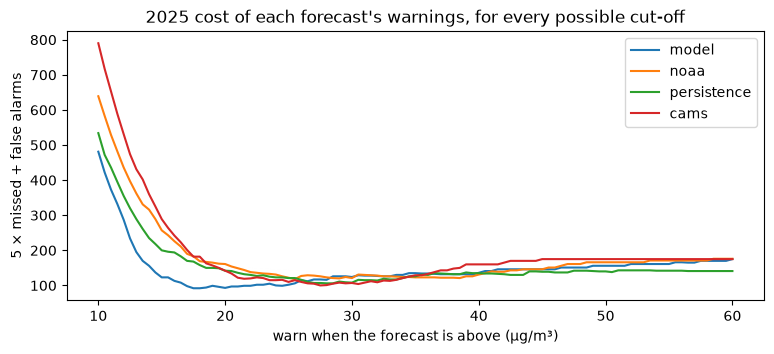

In [16]:
curves = pd.DataFrame({c.removeprefix("pred_"): cost_by_cut_off(test, c) for c in ["pred_model", "pred_noaa", "pred_persistence", "pred_cams"]},
                      index=CUT_OFFS)
ax = curves.plot(figsize=(9, 3.5), title="2025 cost of each forecast's warnings, for every possible cut-off")
ax.set_xlabel("warn when the forecast is above (µg/m³)"); ax.set_ylabel("5 × missed + false alarms")
print("lowest possible 2025 cost (with hindsight) and where:")
print(pd.DataFrame({"lowest_cost": curves.min(), "at_cut_off": curves.idxmin()}))
print("\n2025 cost at our pre-set cut-offs:", {c: int(curves.loc[warn_at["pred_" + c], c]) for c in curves})

**By city, and smoke days vs clean days** (average error, µg/m³)

In [17]:
by_city = test.groupby("city").apply(lambda g: pd.Series({c.removeprefix("pred_"): score(g, c)["mae"] for c in FORECASTS}),
                                     include_groups=False)
by_smoke = test.groupby("is_smoke_day").apply(lambda g: pd.Series({c.removeprefix("pred_"): score(g, c)["mae"] for c in FORECASTS}),
                                              include_groups=False)
print(by_city, "\n")
print(by_smoke.rename(index={False: "clean (no medium/heavy plume)", True: "smoke day"}))

             persistence  climatology  noaa  cams  model
city                                                    
Chicago             3.28         4.22  3.07  3.95   2.20
Detroit             3.60         4.66  3.19  3.27   2.26
Madison             3.30         4.26  3.06  3.35   2.35
Milwaukee           3.47         4.68  3.25  3.27   2.41
Minneapolis         3.95         4.88  3.97  4.58   2.72
St. Louis           2.81         3.27  2.67  3.86   2.20 

                               persistence  climatology   noaa   cams  model
is_smoke_day                                                                
clean (no medium/heavy plume)         3.02         3.82   2.75   3.31   2.02
smoke day                             9.86        12.99  10.82  10.53   8.09


## 9. The demo day: Thursday, July 31, 2025 in Chicago

On July 30, Chicago measured 12 µg/m³. On the 31st it measured 66.

In [18]:
week = test[(test["city"] == "Chicago") & test["date"].between("2025-07-29", "2025-08-03")]
print({c: warn_at[c] for c in ["pred_persistence", "pred_noaa", "pred_cams", "pred_model"]}, "<- warn above these")
print(week[["date", "obs_pm25", "pred_persistence", "pred_noaa", "pred_cams", "pred_model", "region_max_today", "smoke_today"]]
      .round(1).to_string(index=False))

{'pred_persistence': 37.0, 'pred_noaa': 52.5, 'pred_cams': 30.0, 'pred_model': 32.0} <- warn above these
      date  obs_pm25  pred_persistence  pred_noaa  pred_cams  pred_model  region_max_today  smoke_today
2025-07-29       9.4               8.2        8.8       19.6         8.0               8.5          1.0
2025-07-30      12.4               9.4        9.3       17.1         9.2               9.9          2.0
2025-07-31      65.6              12.4       13.7       34.3        15.3              50.6          2.0
2025-08-01      45.5              65.6        8.7       19.1        51.8              83.7          2.0
2025-08-02      26.2              45.5       11.4       13.0        26.0              75.3          2.0
2025-08-03      31.9              26.2       25.2       34.2        17.6              47.4          2.0


## 10. Limits we know about

- **One smoke event dominates training.** 36 of the 38 bad training days are from 2023, mostly one June event.
  Going back to 2018 doesn't fix this: those years add only 3 smoke bad days (section 6).
- **"Today" isn't fully known in the evening.** We use today's full-day average; at 6 pm the last hours are missing.
- **Smoke maps use UTC days**, 5-6 hours ahead of Chicago, and analysts may finish them late in the day.
  Light plumes don't count as smoke days, and 12 of the 35 bad test days had only a light plume or none.
- **Weather mismatch:** trained on near-real weather, tested on day-ahead forecasts (section 7).
- **CAMS is a 45 km model estimate**, and its archive isn't a real day-ahead forecast (section 5).
- **NOAA upgraded its forecast model in May 2024.** Most training rows have the older model's forecast as an
  input, and 2025 has only the new one, so the model learned how far to trust a forecast that has since changed.
- **The afternoon reading** (2-7 PM standard time) is known by about 8 PM in summer, a little later than 6 PM.
- **EPA's archive is the checked copy.** In real use the readings would come from AirNow's live feed, which can
  differ slightly before EPA checks it.
- Six cities, 2.4 years of training data. Monitors are averaged over each metro area, so one neighbourhood can be worse.

## 11. Save the forecasts for the app

In [19]:
metrics = {
    "threshold": THRESHOLD,
    "cost_of_a_miss": COST_OF_A_MISS,
    "warn_at": {c: warn_at[c] for c in FORECASTS},
    "test_period": [test["date"].min(), test["date"].max()],
    "overall": {c: score(test, c) for c in FORECASTS},
    "by_city": {city: {c: score(g, c) for c in FORECASTS} for city, g in test.groupby("city")},
    "by_smoke": {("smoke_day" if k else "clean_day"): {c: score(g, c) for c in FORECASTS} for k, g in test.groupby("is_smoke_day")},
    "training_years_out_of_fold": {c: score(train, c) for c in FORECASTS},
}
train["is_smoke_day"] = train["smoke"] >= 2
cols = ["date", "city", "lat", "lon", "obs_pm25"] + FORECASTS + ["is_smoke_day", "split"]
cols += ["range_lo", "range_hi"]  # not pred_*: the app shows every pred_* column as its own forecaster
metrics["forecast_range"] = {"method": "10th-90th percentile of training out-of-fold misses, by forecast level",
                             "level": 0.8, "bin_edges": RANGE_EDGES, "offsets_low_high": offsets.round(2).values.tolist(),
                             "coverage_train_in_sample": coverage(train), "coverage_test": coverage(test)}
os.makedirs("data", exist_ok=True)
out = pd.concat([train[cols], test[cols]]).sort_values(["city", "date"])
out.round(2).assign(obs_pm25=out["obs_pm25"].round(3)).to_csv("data/predictions.csv", index=False)  # 3 decimals: see fetch_data.py
with open("data/metrics.json", "w") as f:
    json.dump(metrics, f, indent=1)
print("saved data/predictions.csv and data/metrics.json")

saved data/predictions.csv and data/metrics.json


## Sources

- **EPA AirData** daily and hourly PM2.5 (parameter 88101), https://aqs.epa.gov/aqsweb/airdata/download_files.html
- **CAMS global atmospheric composition forecasts** (Copernicus Atmosphere Monitoring Service) via the
  **Open-Meteo Air Quality API**, https://open-meteo.com/en/docs/air-quality-api
- **Open-Meteo** Historical Forecast API and Previous Runs API (weather), https://open-meteo.com
- **NOAA National Air Quality Forecast Capability (NAQFC)** PM2.5 forecasts, NOAA Open Data on AWS,
  https://registry.opendata.aws/noaa-nws-naqfc-pds/ (bias-corrected 24-hour average, CONUS 5 km grid)
- **NOAA Hazard Mapping System** smoke polygons, https://www.ospo.noaa.gov/products/land/hms.html
- Libraries: pandas, NumPy, scikit-learn, matplotlib, pyshp, eccodes (reads NOAA's GRIB files), jupytext
- AI tools: Claude (Anthropic), through Claude Code. It wrote most of the code (data scripts, this notebook, the app)
  and ran the experiments, researched which datasets and forecast archives to use, and drafted the write-up.
  We chose the track and project and picked which ideas to try from the options it proposed.